# Análisis de rendimiento de la experiencia VR

Se analiza el rendimiento técnico de la experiencia de realidad virtual, ejecutada principalmente mediante el build `.exe` en PC a través de Quest Link, modalidad utilizada en la mayoría de las pruebas realizadas. Adicionalmente, se incorpora evidencia de la ejecución del archivo `.apk` en Meta Quest 3S, con el propósito de complementar el análisis y evaluar las condiciones de funcionamiento de la experiencia en diferentes entornos.

Las mediciones recopiladas permiten documentar el comportamiento de la experiencia inmersiva, particularmente durante la ejecución de la secuencia de escenas sincronizadas. Para ello, se examinan indicadores de rendimiento como la carga de CPU y GPU, la latencia, el comportamiento por fotograma y los posibles eventos de fallo registrados durante las pruebas.

### Fuentes de datos

- **`OculusDebugPerformanceProfiler_EDAOP*.csv`**: Tres capturas de rendimiento correspondientes a la ejecución del build `.exe` en PC mediante Quest Link. Constituyen la principal fuente de evidencia, debido a que la mayoría de las pruebas se realizó bajo esta modalidad. Cada archivo representa una ejecución independiente y contiene mediciones registradas por fotograma.

- **`com.MCG3.PUNKOVR#*.csv`**: Tres capturas obtenidas mediante OVR Metrics Tool durante la ejecución del archivo `.apk` en Meta Quest 3S. Estos archivos contienen mediciones registradas aproximadamente cada segundo, las cuales se analizan y resumen por ejecución para caracterizar el rendimiento del dispositivo.

### Consideraciones del análisis

Los datos obtenidos del build `.exe` mediante Quest Link y las métricas correspondientes al archivo `.apk` en Meta Quest 3S se analizan por separado, debido a las diferencias entre sus plataformas, recursos de hardware y entornos de ejecución.

Esta separación permite evitar comparaciones directas entre mediciones que no necesariamente representan las mismas condiciones de funcionamiento. De esta manera, los resultados de Quest Link constituyen la evidencia principal del rendimiento de la experiencia durante las pruebas, mientras que los registros de Meta Quest 3S proporcionan información complementaria sobre su comportamiento en ejecución autónoma.


# 1. Preparación del entorno

In [1]:
from pathlib import Path
import re, sys
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display

In [2]:
# paths
ROOT = Path.cwd()
print(ROOT)

# paths de los logs
LOG_DIR = ROOT / "rendimiento" if (ROOT / "rendimiento").exists() else ROOT
LOG_DIR_APK = LOG_DIR / "apk"
LOG_DIR_EXE = LOG_DIR / "exe"
# paths de los resultados
OUT = LOG_DIR / "resultados_rendimiento"
OUT.mkdir(parents=True, exist_ok=True)
sys.path.insert(0, str(LOG_DIR))

#comprobar paths
FULL_LOG_PATH = LOG_DIR_APK  / "quest_logcatEDAOP_FULLEXP"
OVR_PATHS = sorted(LOG_DIR_APK.glob("com.MCG3.PUNKOVR#*.csv"))
PROFILER_PATHS = sorted(LOG_DIR_EXE.glob("OculusDebugPerformanceProfiler_EDAOP*.csv"))
if not FULL_LOG_PATH.exists():
    raise FileNotFoundError(f"No se encontro el Logcat FULLEXP: {FULL_LOG_PATH}")
if not OVR_PATHS:
    raise FileNotFoundError(f"No se encontraron CSV de OVR Metrics Tool en {LOG_DIR}")


c:\Users\angel\OneDrive\Documentos\.universidad\.2026\s2\tg\PG-analisis-resultados\rendimiento


# 2. Carga de los archivos de rendimiento

Se cargan los archivos de rendimiento obtenidos durante las pruebas de la experiencia VR, tanto en PC mediante Quest Link como en Meta Quest 3S. Cada archivo contiene mediciones de una ejecución diferente, lo que permite revisar su comportamiento y posteriormente comparar los resultados entre las corridas de una misma modalidad.

Antes de realizar el analisis, se revisará la información disponible para conocer cómo están organizados los datos, qué variables contienen y si existen valores faltantes o registros que deban revisarse.

In [3]:
# Guardar las corridas originales por separado evita mezclarlas accidentalmente.
profiler_raw_runs = {}
ovr_raw_runs = {}

for indice, path in enumerate(PROFILER_PATHS, start=1):
    df = pd.read_csv(path)
    df.columns = df.columns.astype(str).str.strip()
    profiler_raw_runs[f"PC/Quest Link {indice}"] = df

for indice, path in enumerate(OVR_PATHS, start=1):
    df = pd.read_csv(path)
    df.columns = df.columns.astype(str).str.strip()
    ovr_raw_runs[f"Quest 3S {indice}"] = df

print(f"Capturas cargadas: {len(profiler_raw_runs)} del EXE y {len(ovr_raw_runs)} del APK")

Capturas cargadas: 3 del EXE y 3 del APK


# 3. EDA - Análisis exploratorio
Antes de analizar el rendimiento, se revisan las características de los archivos: cuántos registros tienen, qué columnas contienen, de qué tipo son sus valores y si hay datos faltantes o repetidos. Esta exploración ayuda a detectar problemas que podrían afectar los resultados posteriores.

### 3.1. Tamaño y primeras filas

Para empezar, se observa el tamaño de cada captura y algunas de sus primeras filas. Esto permite comprobar que la información se cargó correctamente e identificar cómo se presentan las mediciones.

In [4]:
resumen_archivos = []
for modalidad, corridas in [("EXE", profiler_raw_runs), ("APK", ovr_raw_runs)]:
    for nombre, df in corridas.items():
        resumen_archivos.append({
            "modalidad": modalidad, "corrida": nombre,
            "filas": df.shape[0], "columnas": df.shape[1],
            "columnas_duplicadas": int(df.columns.duplicated().sum()),
        })
display(pd.DataFrame(resumen_archivos))

columnas_exe = ["AppFrameIndex", "AppCpuElapsedTime", "AppGpuElapsedTime", "AppMotionToPhotonLatency", "AswIsActive"]
columnas_apk = ["Time Stamp", "average_frame_rate", "display_refresh_rate", "app_gpu_time_microseconds",
                "cpu_utilization_percentage", "gpu_utilization_percentage", "app_pss_MB"]

for nombre, df in profiler_raw_runs.items():
    print(f"\n{nombre}: primeras 5 filas (columnas principales)")
    display(df[[col for col in columnas_exe if col in df.columns]].head(5))

for nombre, df in ovr_raw_runs.items():
    print(f"\n{nombre}: primeras 5 filas (columnas principales)")
    display(df[[col for col in columnas_apk if col in df.columns]].head(5))

,modalidad,corrida,filas,columnas,columnas_duplicadas
0,EXE,PC/Quest Link 1,15637,18,0
1,EXE,PC/Quest Link 2,16249,18,0
2,EXE,PC/Quest Link 3,16044,18,0
3,APK,Quest 3S 1,278,142,0
4,APK,Quest 3S 2,229,142,0
5,APK,Quest 3S 3,218,142,0



PC/Quest Link 1: primeras 5 filas (columnas principales)


,AppFrameIndex,AppCpuElapsedTime,AppGpuElapsedTime,AppMotionToPhotonLatency,AswIsActive
0,0,0.000000,0.000000,0.000000,0
1,-1,0.000582,0.000000,0.000000,0
2,0,0.001537,0.000000,0.000000,0
3,1,0.016955,0.000000,0.065328,0
4,2,0.001876,0.002259,0.051460,0



PC/Quest Link 2: primeras 5 filas (columnas principales)


,AppFrameIndex,AppCpuElapsedTime,AppGpuElapsedTime,AppMotionToPhotonLatency,AswIsActive
0,0,0.001633,0.000000e+00,0.000000,0
1,2,0.001816,8.000000e-07,0.047848,0
2,3,0.001803,1.633300e-03,0.048163,0
3,4,0.000863,1.425400e-03,0.048181,0
4,5,0.001011,3.164000e-04,0.047453,0


...

,Time Stamp,average_frame_rate,display_refresh_rate,app_gpu_time_microseconds,cpu_utilization_percentage,gpu_utilization_percentage,app_pss_MB
0,1000,72,72,1169,99,25,513
1,2000,73,72,1188,77,19,513
2,3000,55,72,9105,45,19,513
3,4000,73,72,3861,46,30,513
4,5000,73,72,4445,45,34,513



Quest 3S 2: primeras 5 filas (columnas principales)


,Time Stamp,average_frame_rate,display_refresh_rate,app_gpu_time_microseconds,cpu_utilization_percentage,gpu_utilization_percentage,app_pss_MB
0,1000,73,72,1275,35,28,530
1,2001,73,72,1001,89,20,530
2,3000,73,72,1081,93,12,530
3,4001,61,72,4021,88,25,530
4,5001,70,72,4229,29,31,530



Quest 3S 3: primeras 5 filas (columnas principales)


,Time Stamp,average_frame_rate,display_refresh_rate,app_gpu_time_microseconds,cpu_utilization_percentage,gpu_utilization_percentage,app_pss_MB
0,1000,72,72,753,47,21,530
1,2000,73,72,835,26,15,530
2,3000,48,72,3940,51,18,530
3,4000,70,72,4251,26,29,530
4,5000,73,72,4268,34,34,530


### 3.2. Nombres de columnas y estructura


In [5]:
for modalidad, corridas in [("EXE", profiler_raw_runs), ("APK", ovr_raw_runs)]:
    nombre_base, df_base = next(iter(corridas.items()))
    print(f"\n===== {modalidad}: nombres de columnas ({len(df_base.columns)}) =====")
    for numero, columna in enumerate(df_base.columns, start=1):
        print(f"{numero:03d}. {columna}")
    print(f"\nTipos de datos y valores presentes en {nombre_base}:")
    df_base.info(verbose=True, show_counts=True)

    base_cols = set(df_base.columns)
    comparacion = []
    for nombre, df in corridas.items():
        comparacion.append({
            "corrida": nombre, "total_columnas": len(df.columns),
            "faltan_respecto_a_primera": ", ".join(sorted(base_cols - set(df.columns))) or "—",
            "adicionales_respecto_a_primera": ", ".join(sorted(set(df.columns) - base_cols)) or "—",
        })
    display(pd.DataFrame(comparacion))


===== EXE: nombres de columnas (18) =====
001. HmdVsyncIndex
002. AppFrameIndex
003. AppDroppendFrameCount
004. AppMotionToPhotonLatency
005. AppQueueAheadTime
006. AppCpuElapsedTime
007. AppGpuElapsedTime
008. CompositorFrameIndex
009. CompositorDroppedFrameCount
010. CompositorLatency
011. CompositorCpuElapsedTime
012. CompositorGpuElapsedTime
013. CompositorCpuStartToGpuEndElapsedTime
014. CompositorGpuEndToVsyncElapsedTime
015. AswIsActive
016. AswActivatedToggleCount
017. AswPresentedFrameCount
018. AswFailedFrameCount

Tipos de datos y valores presentes en PC/Quest Link 1:
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 15637 entries, 0 to 15636
Data columns (total 18 columns):
 #   Column                                 Non-Null Count  Dtype  
---  ------                                 --------------  -----  
 0   HmdVsyncIndex                          15637 non-null  int64  
 1   AppFrameIndex                          15637 non-null  int64  
 2   AppDroppendFrameCount      

,corrida,total_columnas,faltan_respecto_a_primera,adicionales_respecto_a_primera
0,PC/Quest Link 1,18,—,—
1,PC/Quest Link 2,18,—,—
2,PC/Quest Link 3,18,—,—



===== APK: nombres de columnas (142) =====
001. Time Stamp
002. available_memory_MB
003. app_pss_MB
004. battery_level_percentage
005. battery_temperature_celcius
006. battery_current_now_milliamps
007. power_count_neg
008. power_count_pos
009. power_current
010. power_current_neg
011. power_current_pos
012. power_level_state
013. power_voltage
014. power_wattage
015. power_wattage_neg
016. power_wattage_pos
017. iad_millimeter
018. shader_hitches
019. cpu_level
020. gpu_level
021. cpu_frequency_MHz
022. gpu_frequency_MHz
023. mem_frequency_MHz
024. minimum_vsyncs
025. extra_latency_mode
026. phase_sync_mode
027. average_frame_rate
028. display_refresh_rate
029. average_prediction_microseconds
030. icfl_mean_microseconds
031. icfl_stdev_microseconds
032. slice_headroom_mean_microseconds
033. slice_headroom_stdev_microseconds
034. slice_gpu_start_delay_min_microseconds
035. slice_gpu_start_delay_max_microseconds
036. screen_tear_count
037. early_frame_count
038. stale_frame_count
039. 

,corrida,total_columnas,faltan_respecto_a_primera,adicionales_respecto_a_primera
0,Quest 3S 1,142,—,—
1,Quest 3S 2,142,—,—
2,Quest 3S 3,142,—,—


### Significado de cada columna en PC/Quest Link

https://developers.meta.com/vr/documentation/native/pc/dg-performance-stats/

### 3.3 tipos de datos

In [6]:
tipos_por_corrida = []
for modalidad, corridas in [("EXE", profiler_raw_runs), ("APK", ovr_raw_runs)]:
    for nombre, df in corridas.items():
        conteo = df.dtypes.astype(str).value_counts()
        for tipo, cantidad in conteo.items():
            tipos_por_corrida.append({"modalidad": modalidad, "corrida": nombre,
                                     "tipo_detectado": tipo, "columnas": int(cantidad)})
display(pd.DataFrame(tipos_por_corrida))

for modalidad, corridas in [("EXE", profiler_raw_runs), ("APK", ovr_raw_runs)]:
    nombre, df = next(iter(corridas.items()))
    print(f"{modalidad} | Columnas de texto en {nombre}: {list(df.select_dtypes(include=['object', 'string']).columns)}")

,modalidad,corrida,tipo_detectado,columnas
0,EXE,PC/Quest Link 1,int64,9
1,EXE,PC/Quest Link 1,float64,9
2,EXE,PC/Quest Link 2,int64,9
3,EXE,PC/Quest Link 2,float64,9
4,EXE,PC/Quest Link 3,int64,9
5,EXE,PC/Quest Link 3,float64,9
6,APK,Quest 3S 1,int64,142
7,APK,Quest 3S 2,int64,142
8,APK,Quest 3S 3,int64,142


EXE | Columnas de texto en PC/Quest Link 1: []
APK | Columnas de texto en Quest 3S 1: []


### 3.4 Valores faltantes

In [7]:
def tabla_faltantes(df):
    cantidad = df.isna().sum()
    return pd.DataFrame({
        "columna": df.columns,
        "tipo": df.dtypes.astype(str).to_numpy(),
        "faltantes": cantidad.to_numpy(),
        "faltantes_pct": (100 * cantidad / len(df)).to_numpy() if len(df) else np.full(len(df.columns), np.nan),
    }).sort_values(["faltantes_pct", "columna"], ascending=[False, True])

faltantes_por_corrida = {}
for modalidad, corridas in [("EXE", profiler_raw_runs), ("APK", ovr_raw_runs)]:
    for nombre, df in corridas.items():
        faltantes = tabla_faltantes(df)
        faltantes_por_corrida[nombre] = faltantes
        print(f"\n{nombre}: {int((faltantes.faltantes > 0).sum())} columnas con algún valor faltante")
        display(faltantes[faltantes.faltantes > 0].head(15).round(2))


PC/Quest Link 1: 0 columnas con algún valor faltante


,columna,tipo,faltantes,faltantes_pct



PC/Quest Link 2: 0 columnas con algún valor faltante


,columna,tipo,faltantes,faltantes_pct



PC/Quest Link 3: 0 columnas con algún valor faltante


...

,columna,tipo,faltantes,faltantes_pct



Quest 3S 2: 0 columnas con algún valor faltante


,columna,tipo,faltantes,faltantes_pct



Quest 3S 3: 0 columnas con algún valor faltante


,columna,tipo,faltantes,faltantes_pct


### Duplicados indices y valores que requieren de revision

In [8]:
revision_raw = []
for nombre, df in profiler_raw_runs.items():
    indice = pd.to_numeric(df.get("AppFrameIndex", pd.Series(np.nan, index=df.index)), errors="coerce")
    tiempos = [col for col in ["AppCpuElapsedTime", "AppGpuElapsedTime", "AppMotionToPhotonLatency"]
               if col in df.columns]
    tiempos_num = df[tiempos].apply(pd.to_numeric, errors="coerce") if tiempos else pd.DataFrame(index=df.index)
    revision_raw.append({
        "modalidad": "EXE", "corrida": nombre,
        "filas_duplicadas_exacto": int(df.duplicated().sum()),
        "identificadores_invalidos": int((~indice.ge(0)).sum()),
        "indices_repetidos": int(indice.dropna().duplicated().sum()),
        "filas_tiempos_cero": int(tiempos_num.eq(0).all(axis=1).sum()) if len(tiempos) == 3 else np.nan,
    })

for nombre, df in ovr_raw_runs.items():
    ts = pd.to_numeric(df.get("Time Stamp", pd.Series(np.nan, index=df.index)), errors="coerce")
    revision_raw.append({
        "modalidad": "APK", "corrida": nombre,
        "filas_duplicadas_exacto": int(df.duplicated().sum()),
        "identificadores_invalidos": int(ts.isna().sum()),
        "indices_repetidos": int(ts.dropna().duplicated().sum()),
        "filas_tiempos_cero": np.nan,
    })
display(pd.DataFrame(revision_raw))

,modalidad,corrida,filas_duplicadas_exacto,identificadores_invalidos,indices_repetidos,filas_tiempos_cero
0,EXE,PC/Quest Link 1,0,1,1,1.0
1,EXE,PC/Quest Link 2,0,0,1,1.0
2,EXE,PC/Quest Link 3,0,1,1,1.0
3,APK,Quest 3S 1,0,0,0,NaN
4,APK,Quest 3S 2,0,0,0,NaN
5,APK,Quest 3S 3,0,0,0,NaN


### 3.6 Primeras estadisticas de las variables principales

Una vez conocida la estructura, se calculan valores sencillos como el mínimo, máximo, media y percentiles. Esto ofrece una primera idea de qué tan variables son las mediciones y ayuda a detectar resultados extremos que conviene revisar más adelante.

En el profiler de PC, los tiempos se muestran en milisegundos únicamente para facilitar su lectura; los CSV originales no se modifican.

In [9]:
variables_exe = ["AppCpuElapsedTime", "AppGpuElapsedTime", "AppMotionToPhotonLatency"]
variables_apk = ["average_frame_rate", "app_gpu_time_microseconds",
                 "cpu_utilization_percentage", "gpu_utilization_percentage", "app_pss_MB"]

for nombre, df in profiler_raw_runs.items():
    seleccion = [col for col in variables_exe if col in df.columns]
    numericas = df[seleccion].apply(pd.to_numeric, errors="coerce") * 1000
    print(f"\n{nombre} — tiempos originales convertidos a ms (incluyen valores pendientes de depuración)")
    display(numericas.describe(percentiles=[.05, .5, .95]).round(3).T)

for nombre, df in ovr_raw_runs.items():
    seleccion = [col for col in variables_apk if col in df.columns]
    numericas = df[seleccion].apply(pd.to_numeric, errors="coerce").copy()
    if "app_gpu_time_microseconds" in numericas:
        numericas["app_gpu_time_ms"] = numericas.pop("app_gpu_time_microseconds") / 1000
    print(f"\n{nombre} — estadísticas iniciales")
    display(numericas.describe(percentiles=[.05, .5, .95]).round(3).T)


PC/Quest Link 1 — tiempos originales convertidos a ms (incluyen valores pendientes de depuración)


,count,mean,std,min,5%,50%,95%,max
AppCpuElapsedTime,15637.0,1.378,4.618,0.0,0.912,1.252,2.095,576.533
AppGpuElapsedTime,15637.0,1.805,0.839,0.0,0.657,1.597,3.537,15.925
AppMotionToPhotonLatency,15637.0,42.741,7.679,0.0,40.602,42.541,44.508,623.799



PC/Quest Link 2 — tiempos originales convertidos a ms (incluyen valores pendientes de depuración)


,count,mean,std,min,5%,50%,95%,max
AppCpuElapsedTime,16249.0,1.556,5.407,0.0,0.963,1.416,2.335,688.273
AppGpuElapsedTime,16249.0,1.746,0.731,0.0,0.616,1.622,3.312,7.485
AppMotionToPhotonLatency,16249.0,42.242,8.522,0.0,40.349,41.896,44.641,749.047



PC/Quest Link 3 — tiempos originales convertidos a ms (incluyen valores pendientes de depuración)


...

,count,mean,std,min,5%,50%,95%,max
average_frame_rate,278.0,70.482,5.617,43.000,54.850,72.000,73.000,73.000
cpu_utilization_percentage,278.0,72.094,21.602,19.000,26.000,72.000,100.000,100.000
gpu_utilization_percentage,278.0,54.349,20.505,18.000,30.000,52.000,97.000,98.000
app_pss_MB,278.0,1181.129,302.254,513.000,513.000,1329.000,1548.000,1548.000
app_gpu_time_ms,278.0,7.106,3.877,1.169,3.527,6.277,16.353,19.276



Quest 3S 2 — estadísticas iniciales


,count,mean,std,min,5%,50%,95%,max
average_frame_rate,229.0,69.157,8.602,3.0,49.000,72.000,73.000,73.000
cpu_utilization_percentage,229.0,49.507,27.489,16.0,23.000,36.000,98.000,100.000
gpu_utilization_percentage,229.0,58.769,21.163,9.0,25.000,55.000,98.000,98.000
app_pss_MB,229.0,1240.716,324.839,530.0,530.000,1355.000,1598.000,1598.000
app_gpu_time_ms,229.0,8.110,4.919,0.0,1.995,6.564,19.338,30.022



Quest 3S 3 — estadísticas iniciales


,count,mean,std,min,5%,50%,95%,max
average_frame_rate,218.0,69.917,6.563,32.000,55.000,72.000,73.000,73.000
cpu_utilization_percentage,218.0,48.431,28.439,16.000,22.000,33.000,98.000,100.000
gpu_utilization_percentage,218.0,60.367,20.269,15.000,28.550,55.000,97.000,98.000
app_pss_MB,218.0,1295.376,290.569,530.000,530.000,1359.000,1605.000,1605.000
app_gpu_time_ms,218.0,7.925,3.876,0.753,3.299,6.731,15.857,20.199


### 3.7 Intervalos de muestreo y frecuencia del visor APK

Se revisa cada cuánto tiempo se registraron las muestras del APK y qué frecuencia de refresco aparece en los archivos. Esta información ayuda a interpretar las gráficas: el tiempo de captura no necesariamente coincide con el inicio o la duración de la canción.

In [10]:
intervalos = []
for nombre, df in ovr_raw_runs.items():
    ts = pd.to_numeric(df["Time Stamp"], errors="coerce") if "Time Stamp" in df else pd.Series(dtype=float)
    ordenado = ts.dropna().sort_values().drop_duplicates()
    paso_s = ordenado.diff() / 1000
    refresh = pd.to_numeric(df["display_refresh_rate"], errors="coerce") if "display_refresh_rate" in df else pd.Series(dtype=float)
    intervalos.append({
        "corrida": nombre,
        "intervalos": int(paso_s.count()),
        "paso_mediano_s": paso_s.median(),
        "paso_maximo_s": paso_s.max(),
        "intervalos_mayores_2s": int(paso_s.gt(2).sum()),
        "refresco_observado_Hz": ", ".join(str(x) for x in sorted(refresh.dropna().unique())),
    })
display(pd.DataFrame(intervalos).round(3))

,corrida,intervalos,paso_mediano_s,paso_maximo_s,intervalos_mayores_2s,refresco_observado_Hz
0,Quest 3S 1,277,1.0,1.047,0,72
1,Quest 3S 2,228,1.0,1.044,0,72
2,Quest 3S 3,217,1.0,1.998,0,72


# 4. Preparación y validación de datos
se preparan los registros que se utilizarán en los resultados. Se convierten las unidades de tiempo, se identifican las mediciones válidas y se documenta cuántos registros quedan después de aplicar los criterios de limpieza.

Las corridas originales permanecen guardadas en `profiler_raw_runs` y `ovr_raw_runs`, mientras que las versiones preparadas se almacenan por separado para poder verificar cualquier decisión.

In [11]:
TARGET_FPS = 72.0  # Referencia configurable: comprobarla con display_refresh_rate.
GPU_BUDGET_MS = 1000.0 / TARGET_FPS
COLORS = ["#3B6FB6", "#E17C05", "#2A9D8F", "#7B2CBF"]

inventory_rows, quality_rows, metric_quality_rows = [], [], []

def descriptivos(serie):
    valores = pd.to_numeric(serie, errors="coerce").replace([np.inf, -np.inf], np.nan).dropna()
    if valores.empty:
        return {k: np.nan for k in ["media", "DE", "mediana", "p05", "p95", "minimo", "maximo"]} | {"n": 0}
    return {
        "n": len(valores), "media": valores.mean(), "DE": valores.std(ddof=1),
        "mediana": valores.median(), "p05": valores.quantile(.05),
        "p95": valores.quantile(.95), "minimo": valores.min(), "maximo": valores.max(),
    }

def auditar_metrica(fuente, corrida, metrica, serie):
    valores = pd.to_numeric(serie, errors="coerce").replace([np.inf, -np.inf], np.nan)
    metric_quality_rows.append({
        "fuente": fuente, "corrida": corrida, "metrica": metrica,
        "muestras": len(valores), "validas": int(valores.notna().sum()),
        "faltantes": int(valores.isna().sum()), "ceros": int(valores.eq(0).sum()),
    })

### 4.1 preparacion de las capturas del .exe 
Se conservan los fotogramas con un índice válido y se excluyen los registros cuyos tres tiempos principales son cero, siguiendo el criterio del análisis original. Si un índice de fotograma está repetido, se conserva la última observación. Los tiempos se convierten de segundos a milisegundos.

Los contadores acumulados de fotogramas descartados se revisan **en el orden original del archivo**, porque ordenarlos por índice podría alterar la interpretación de los reinicios.

In [12]:
profiler_required = {
    "AppFrameIndex", "AppDroppendFrameCount", "CompositorDroppedFrameCount",
    "AppMotionToPhotonLatency", "AppCpuElapsedTime", "AppGpuElapsedTime", "AswIsActive",
}
pc_metrics = [
    ("AppCpuElapsedTime", "CPU_app"),
    ("AppGpuElapsedTime", "GPU_app"),
    ("AppMotionToPhotonLatency", "movimiento_foton"),
]

profiler_runs, profiler_rows, profiler_stats_rows = {}, [], []
for nombre, original in profiler_raw_runs.items():
    faltan = profiler_required - set(original.columns)
    if faltan:
        raise ValueError(f"{nombre}: faltan columnas requeridas: {sorted(faltan)}")

    raw = original.copy()
    for col in profiler_required:
        raw[col] = pd.to_numeric(raw[col], errors="coerce").replace([np.inf, -np.inf], np.nan)

    index_ok = raw["AppFrameIndex"].ge(0)
    tiempos = [col for col, _ in pc_metrics]
    all_zero = raw[tiempos].eq(0).all(axis=1)
    candidatas = raw.loc[index_ok & ~all_zero].copy()
    duplicados = int(candidatas["AppFrameIndex"].duplicated().sum())
    frames = candidatas.drop_duplicates("AppFrameIndex", keep="last").sort_values("AppFrameIndex").copy()

    fila = {"corrida": nombre, "muestras_fotograma": len(frames)}
    for col, etiqueta in pc_metrics:
        frames[f"{col}_ms"] = (frames[col] * 1000).where(frames[col].ge(0))
        valores = frames[f"{col}_ms"]
        fila[f"{etiqueta}_mediana_ms"] = valores.median()
        fila[f"{etiqueta}_p95_ms"] = valores.quantile(.95)
        profiler_stats_rows.append({"corrida": nombre, "metrica": etiqueta, "unidad": "ms", **descriptivos(valores)})
        auditar_metrica("EXE", nombre, etiqueta, valores)

    frames["AswIsActive_num"] = frames["AswIsActive"].where(frames["AswIsActive"].isin([0, 1]))
    asw = frames["AswIsActive_num"].dropna()
    fila["ASW_activo_pct"] = 100 * asw.eq(1).mean() if len(asw) else np.nan

    for col, etiqueta in [("AppDroppendFrameCount", "app"),
                          ("CompositorDroppedFrameCount", "compositor")]:
        contador = raw[col].where(raw[col].ge(0)).dropna()
        reinicios = int(contador.diff().lt(0).sum())
        fila[f"{etiqueta}_reinicios_contador"] = reinicios
        fila[f"{etiqueta}_incremento_descartados"] = (
            float(contador.iloc[-1] - contador.iloc[0]) if len(contador) and reinicios == 0 else np.nan
        )

    profiler_runs[nombre] = frames
    profiler_rows.append(fila)
    inventory_rows.append({
        "fuente": "EXE", "corrida": nombre, "filas_originales": len(raw),
        "muestras_analizadas": len(frames), "duracion_observada_s": np.nan, "paso_mediano_s": np.nan,
    })
    quality_rows.append({
        "fuente": "EXE", "corrida": nombre, "indices_invalidos": int((~index_ok).sum()),
        "filas_tiempos_cero": int(all_zero.sum()), "duplicados_eliminados": duplicados,
        "retrocesos_indice_original": int(raw["AppFrameIndex"].diff().lt(0).sum()),
        "reinicios_contador_app": fila["app_reinicios_contador"],
        "reinicios_contador_compositor": fila["compositor_reinicios_contador"],
    })

profiler_summary = pd.DataFrame(profiler_rows)
profiler_descriptive = pd.DataFrame(profiler_stats_rows)
# Indicador descriptivo aproximado, no una medida oficial de tasa de frames perdidos.
profiler_summary["descartes_sobre_muestras_pct"] = (
    100 * profiler_summary["app_incremento_descartados"] / profiler_summary["muestras_fotograma"].replace(0, np.nan)
)

### 4.1 preparacion de las capturas del APK 

Para las capturas del visor se revisan las marcas de tiempo, se eliminan las que no pueden interpretarse y se evita contar dos veces una misma muestra temporal. Después se convierten los tiempos de GPU a milisegundos y se calculan medidas resumidas para cada corrida.

La referencia de **72 FPS** se mantiene como parámetro del análisis original, pero conviene contrastarla con la frecuencia real (`display_refresh_rate`) observada en los archivos. Los porcentajes inferiores al objetivo corresponden al **porcentaje de muestras**, no a un recuento directo de fotogramas descartados.


In [13]:
required_ovr = {
    "Time Stamp", "average_frame_rate", "display_refresh_rate", "app_gpu_time_microseconds",
    "cpu_utilization_percentage", "gpu_utilization_percentage",
    "app_pss_MB", "app_rss_MB", "app_uss_MB",
}
optional_ovr = {"stale_frame_count", "shader_hitches"}
ovr_runs, ovr_rows, ovr_stats_rows = {}, [], []

for nombre, original in ovr_raw_runs.items():
    faltan = required_ovr - set(original.columns)
    if faltan:
        raise ValueError(f"{nombre}: faltan columnas requeridas: {sorted(faltan)}")

    df = original.copy()
    for col in required_ovr | (optional_ovr & set(df.columns)):
        df[col] = pd.to_numeric(df[col], errors="coerce").replace([np.inf, -np.inf], np.nan)

    ts_original = df["Time Stamp"].copy()
    repetidas = int(ts_original.dropna().duplicated().sum())
    df = (df.dropna(subset=["Time Stamp"]).sort_values("Time Stamp")
            .drop_duplicates("Time Stamp", keep="last").reset_index(drop=True))
    if df.empty:
        raise ValueError(f"{nombre}: ninguna muestra tiene 'Time Stamp' válido")

    df["tiempo_captura_s"] = (df["Time Stamp"] - df["Time Stamp"].min()) / 1000
    df["fps"] = df["average_frame_rate"]
    df["gpu_ms"] = df["app_gpu_time_microseconds"] / 1000
    for col in ["fps", "gpu_ms", "cpu_utilization_percentage", "gpu_utilization_percentage",
                "app_pss_MB", "app_rss_MB", "app_uss_MB"]:
        df[col] = df[col].where(df[col].ge(0))
    df["corrida"] = nombre
    ovr_runs[nombre] = df

    fps = df["fps"].dropna()
    gpu = df["gpu_ms"].dropna()
    ovr_rows.append({
        "corrida": nombre, "muestras": len(df),
        "duracion_captura_s": df["tiempo_captura_s"].max(),
        "paso_muestreo_mediano_s": df["tiempo_captura_s"].diff().median(),
        "FPS_media": fps.mean(), "FPS_mediana": fps.median(),
        "FPS_p05": fps.quantile(.05), "FPS_p95": fps.quantile(.95),
        "muestras_bajo_72FPS_pct": 100 * fps.lt(TARGET_FPS).mean() if len(fps) else np.nan,
        "muestras_bajo_64_8FPS_pct": 100 * fps.lt(.9 * TARGET_FPS).mean() if len(fps) else np.nan,
        "GPU_mediana_ms": gpu.median(), "GPU_p95_ms": gpu.quantile(.95),
        "muestras_GPU_sobre_presupuesto_pct": 100 * gpu.gt(GPU_BUDGET_MS).mean() if len(gpu) else np.nan,
        "CPU_utilizacion_mediana_pct": df["cpu_utilization_percentage"].median(),
        "GPU_utilizacion_mediana_pct": df["gpu_utilization_percentage"].median(),
        "PSS_mediana_MB": df["app_pss_MB"].median(),
        "RSS_mediana_MB": df["app_rss_MB"].median(),
        "USS_mediana_MB": df["app_uss_MB"].median(),
        "frames_obsoletos_mediana": df["stale_frame_count"].median() if "stale_frame_count" in df else np.nan,
        "shader_hitches_mediana": df["shader_hitches"].median() if "shader_hitches" in df else np.nan,
    })

    inventory_rows.append({
        "fuente": "APK_OVR", "corrida": nombre, "filas_originales": len(original),
        "muestras_analizadas": len(df), "duracion_observada_s": df["tiempo_captura_s"].max(),
        "paso_mediano_s": df["tiempo_captura_s"].diff().median(),
    })
    quality_rows.append({
        "fuente": "APK_OVR", "corrida": nombre,
        "timestamps_invalidos": int(ts_original.isna().sum()),
        "duplicados_eliminados": repetidas,
    })

    for col, unidad in [
        ("fps", "FPS"), ("gpu_ms", "ms"), ("cpu_utilization_percentage", "%"),
        ("gpu_utilization_percentage", "%"), ("app_pss_MB", "MB"),
        ("app_rss_MB", "MB"), ("app_uss_MB", "MB"),
    ]:
        auditar_metrica("APK_OVR", nombre, col, df[col])
        ovr_stats_rows.append({"corrida": nombre, "metrica": col, "unidad": unidad, **descriptivos(df[col])})

ovr_summary = pd.DataFrame(ovr_rows)
ovr_descriptive = pd.DataFrame(ovr_stats_rows)

for nombre, df in ovr_runs.items():
    valores = sorted(df["display_refresh_rate"].dropna().unique())
    if valores and not any(np.isclose(v, TARGET_FPS) for v in valores):
        print(f"AVISO — {nombre}: refresco observado {valores} Hz; referencia configurada {TARGET_FPS} FPS.")

### 4.3 comprobacion de la calidad luego de preparar los archivos
se muestra cuántos registros se conservaron y qué situaciones se detectaron durante la limpieza. Esta tabla permite explicar con transparencia el origen de las métricas calculadas y distinguir las mediciones válidas de las que requieren precaución.



In [14]:
inventory = pd.DataFrame(inventory_rows)
quality = pd.DataFrame(quality_rows)
metric_quality = pd.DataFrame(metric_quality_rows)

display(inventory.round(3))
display(quality)
display(metric_quality)

counter_quality = profiler_summary[[
    "corrida", "app_reinicios_contador", "compositor_reinicios_contador",
    "app_incremento_descartados", "compositor_incremento_descartados",
]]
print("Revisión de contadores acumulados del profiler:")
display(counter_quality)

,fuente,corrida,filas_originales,muestras_analizadas,duracion_observada_s,paso_mediano_s
0,EXE,PC/Quest Link 1,15637,15635,NaN,NaN
1,EXE,PC/Quest Link 2,16249,16248,NaN,NaN
2,EXE,PC/Quest Link 3,16044,16042,NaN,NaN
3,APK_OVR,Quest 3S 1,278,278,277.032,1.0
4,APK_OVR,Quest 3S 2,229,229,228.026,1.0
5,APK_OVR,Quest 3S 3,218,218,218.066,1.0


,fuente,corrida,indices_invalidos,filas_tiempos_cero,duplicados_eliminados,retrocesos_indice_original,reinicios_contador_app,reinicios_contador_compositor,timestamps_invalidos
0,EXE,PC/Quest Link 1,1.0,1.0,0,1.0,0.0,0.0,NaN
1,EXE,PC/Quest Link 2,0.0,1.0,0,1.0,0.0,0.0,NaN
2,EXE,PC/Quest Link 3,1.0,1.0,0,1.0,0.0,0.0,NaN
3,APK_OVR,Quest 3S 1,NaN,NaN,0,NaN,NaN,NaN,0.0
4,APK_OVR,Quest 3S 2,NaN,NaN,0,NaN,NaN,NaN,0.0
5,APK_OVR,Quest 3S 3,NaN,NaN,0,NaN,NaN,NaN,0.0


,fuente,corrida,metrica,muestras,validas,faltantes,ceros
0,EXE,PC/Quest Link 1,CPU_app,15635,15635,0,0
1,EXE,PC/Quest Link 1,GPU_app,15635,15635,0,2
2,EXE,PC/Quest Link 1,movimiento_foton,15635,15635,0,1
3,EXE,PC/Quest Link 2,CPU_app,16248,16248,0,0
4,EXE,PC/Quest Link 2,GPU_app,16248,16248,0,1
5,EXE,PC/Quest Link 2,movimiento_foton,16248,16248,0,1
6,EXE,PC/Quest Link 3,CPU_app,16042,16042,0,0
7,EXE,PC/Quest Link 3,GPU_app,16042,16042,0,1
8,EXE,PC/Quest Link 3,movimiento_foton,16042,16042,0,0
9,APK_OVR,Quest 3S 1,fps,278,278,0,0


Revisión de contadores acumulados del profiler:


,corrida,app_reinicios_contador,compositor_reinicios_contador,app_incremento_descartados,compositor_incremento_descartados
0,PC/Quest Link 1,0,0,136.0,3.0
1,PC/Quest Link 2,0,0,138.0,2.0
2,PC/Quest Link 3,0,0,99.0,2.0


# 5. análisis de resultados - EXE en PC por Quest Link

Se observan los tiempos de procesamiento de CPU y GPU, la latencia y la actividad de ASW para entender cómo se comportó la experiencia durante las pruebas. Las corridas se comparan entre sí, sin mezclar sus mediciones con las del APK.

In [15]:
# resumen por corrida del 
display(profiler_summary.round(3))

,corrida,muestras_fotograma,CPU_app_mediana_ms,CPU_app_p95_ms,GPU_app_mediana_ms,GPU_app_p95_ms,movimiento_foton_mediana_ms,movimiento_foton_p95_ms,ASW_activo_pct,app_reinicios_contador,app_incremento_descartados,compositor_reinicios_contador,compositor_incremento_descartados,descartes_sobre_muestras_pct
0,PC/Quest Link 1,15635,1.252,2.095,1.597,3.537,42.542,44.509,0.0,0,136.0,0,3.0,0.870
1,PC/Quest Link 2,16248,1.416,2.335,1.622,3.312,41.896,44.641,0.0,0,138.0,0,2.0,0.849
2,PC/Quest Link 3,16042,1.312,2.268,1.614,3.567,41.969,44.588,0.0,0,99.0,0,2.0,0.617


En las tres capturas se analizaron entre 15,635 y 16,248 fotogramas. Los tiempos medianos de procesamiento de CPU fueron de 1.252, 1.416, 1.312 ms, mientras que los de GPU fueron de 1.597, 1.622, 1.622.  Y en el perceltil 95, los tiempos de CPU no superaron los 2.335 ms y los de GPU 3.567 ms. Acerca de la latencia mediana movimiento-foton estuvo entre 41.896 y 42.542 ms, lo que indica que en todas las pruebas hubo un comportamiento similar. Aunque no se registro alguna actividad de ASW, los contadores de la aplicacion aumentaron en 136, 138 y 99 fotogramas descartados, además de entre 2 a 3 descartes del compositor. Por lo que el comportamiento en general de las tres capturas fue estable, pero tuvo algunas interrupciones. 

In [16]:
# descripcion de cada metrica
display(profiler_descriptive.round(3))

,corrida,metrica,unidad,n,media,DE,mediana,p05,p95,minimo,maximo
0,PC/Quest Link 1,CPU_app,ms,15635,1.378,4.618,1.252,0.912,2.095,0.656,576.533
1,PC/Quest Link 1,GPU_app,ms,15635,1.805,0.839,1.597,0.657,3.537,0.000,15.925
2,PC/Quest Link 1,movimiento_foton,ms,15635,42.746,7.664,42.542,40.603,44.509,0.000,623.799
3,PC/Quest Link 2,CPU_app,ms,16248,1.557,5.408,1.416,0.963,2.335,0.626,688.273
4,PC/Quest Link 2,GPU_app,ms,16248,1.746,0.731,1.622,0.616,3.312,0.000,7.485
5,PC/Quest Link 2,movimiento_foton,ms,16248,42.245,8.516,41.896,40.349,44.641,0.000,749.047
6,PC/Quest Link 3,CPU_app,ms,16042,1.467,4.225,1.312,0.943,2.268,0.635,532.834
7,PC/Quest Link 3,GPU_app,ms,16042,1.773,0.792,1.614,0.640,3.567,0.000,5.613
8,PC/Quest Link 3,movimiento_foton,ms,16042,42.323,6.670,41.969,40.369,44.588,39.132,582.451


Las estadísticas muestran que los tiempos de CPU y GPU fueron bajos, aunque se registraron algunos valores extremos. Las máximos de CPU superaron los 500 ms en las tres pruebas, mientras que sus medianas permanecieron 1.3 m. Esta diferencia indica que los incrementos más elevados fueron poco frecuentes y que no representan el comportamiento en general. Acerca de la latencia se obseva una situación similar, ya que sus medianas se mantienen cerca a 42 ms, aunque hayan registros altos. 

### 5.1 evolución del CPU y GPU

Las siguientes gráficas muestran si el tiempo de procesamiento se mantiene estable o cambia a lo largo de las capturas. Se utiliza una mediana móvil de 120 fotogramas para facilitar la lectura de las tendencias, sin atribuir automáticamente los cambios a una escena específica.


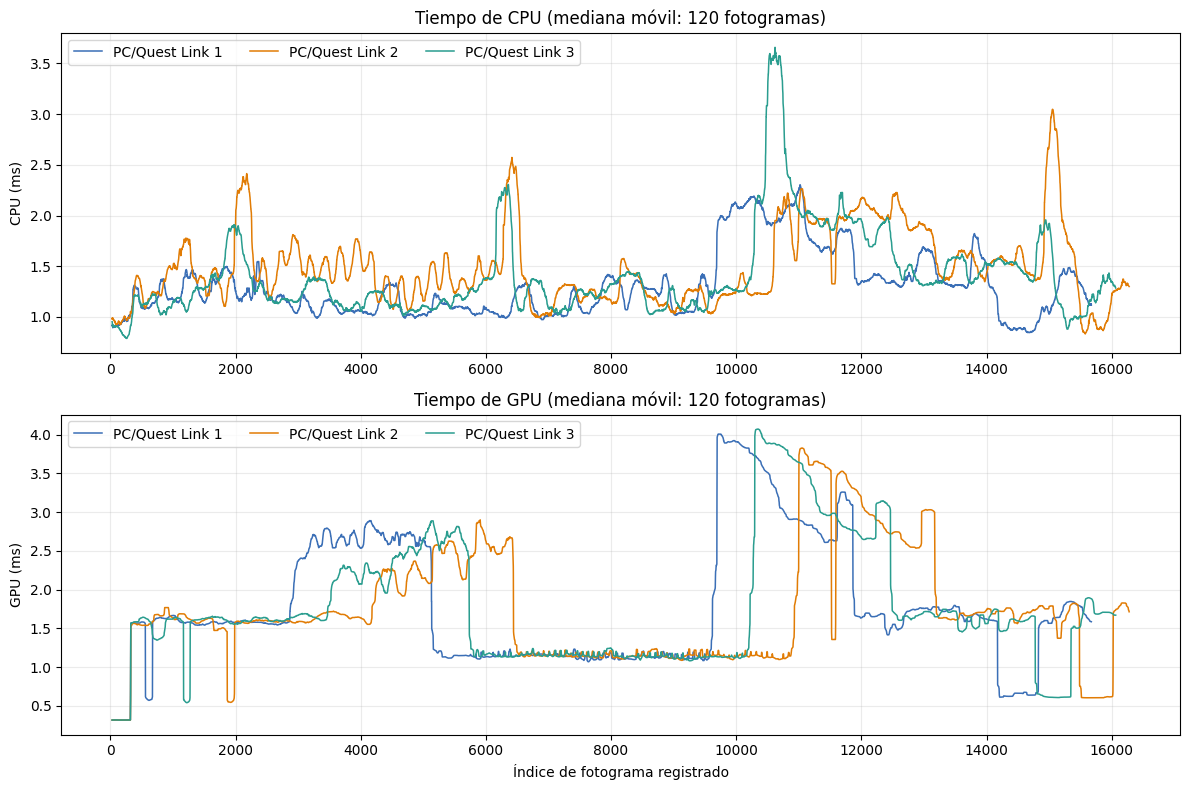

In [17]:
fig, axs = plt.subplots(2, 1, figsize=(12, 8), sharex=False)
for i, (nombre, df) in enumerate(profiler_runs.items()):
    x = df["AppFrameIndex"]
    for ax, col in [(axs[0], "AppCpuElapsedTime_ms"), (axs[1], "AppGpuElapsedTime_ms")]:
        suave = df[col].rolling(120, min_periods=30).median()
        ax.plot(x, suave, color=COLORS[i % len(COLORS)], linewidth=1.1, label=nombre)
axs[0].set(title="Tiempo de CPU (mediana móvil: 120 fotogramas)", ylabel="CPU (ms)")
axs[1].set(title="Tiempo de GPU (mediana móvil: 120 fotogramas)",
           xlabel="Índice de fotograma registrado", ylabel="GPU (ms)")
for ax in axs:
    ax.grid(alpha=.25)
    ax.legend(ncol=3)
fig.tight_layout()
fig.savefig(OUT / "exe_cpu_gpu_evolucion.png", dpi=200, bbox_inches="tight")
plt.show()

En la gráfica de la evolución del CPU se mantiene entre 1 y 2 ms durante las tres capturas. Aunque, se observan incrementos temporales en especifico en la tercera corrida, donde la mediana móvil alcanza aproximadamente 3.6 ms cerca del fotograma 10,700. Mientras uqe la segunda también presenta incrementos importantes en la fase final. Estos cambios indican que existen momentos en los que la aplicación requiere mayor procesamiento, aunque no se observa un aumento continuo durante toda la experiencia. 


Mientras que en la gráfica de los tiempos procesamiento de GPU se muestran periodos que se ven estables, cercanos a 1-2 ms, alternados con incremenros que alcanzan aproximadamente 4 ms en ciertos intervalos. Aunque estos incrementos aparecen en las tres capturas, no ocurren en el los mismos índices de fotogramas. 

Esto lo que puede sugerir es que algunas partes requieren de mayor procesamiento. A pesar de que las mediciones no permitan identificar directamente las escenas de estas variaciones, el tiempo coincide aproximadamente con la escena más pesada de procesar. 

## Latencia y distribución de los tiempos

La latencia permite observar el tiempo transcurrido entre el movimiento y la respuesta visual reportada por el sistema. Además de su evolución, se incluyen diagramas de caja para comparar la dispersión de los tiempos de CPU, GPU y latencia entre las capturas.

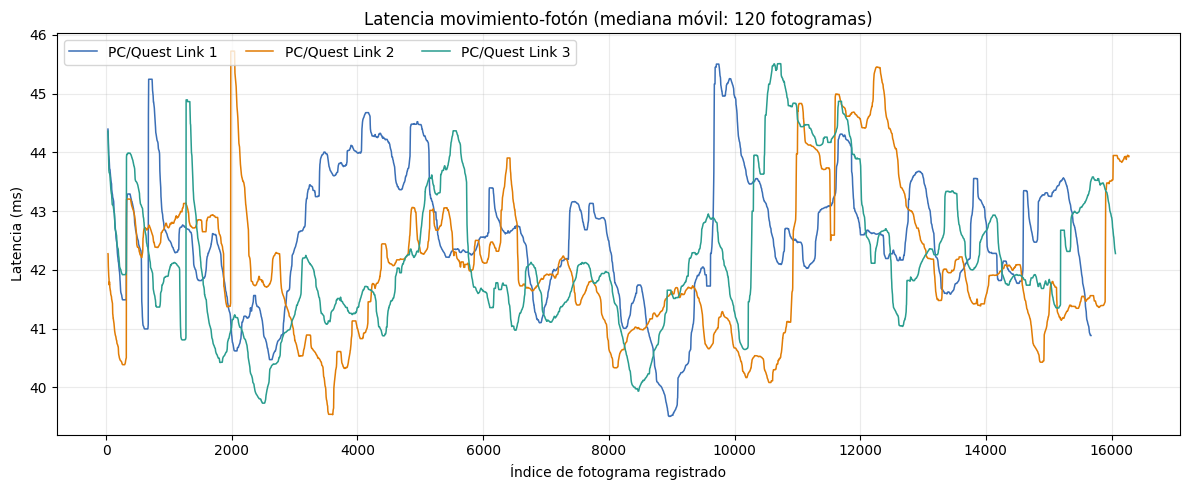

In [18]:
fig, ax = plt.subplots(figsize=(12, 5))
for i, (nombre, df) in enumerate(profiler_runs.items()):
    suave = df["AppMotionToPhotonLatency_ms"].rolling(120, min_periods=30).median()
    ax.plot(df["AppFrameIndex"], suave, color=COLORS[i % len(COLORS)], linewidth=1.1, label=nombre)
ax.set(title="Latencia movimiento-fotón (mediana móvil: 120 fotogramas)",
       xlabel="Índice de fotograma registrado", ylabel="Latencia (ms)")
ax.legend(ncol=3)
ax.grid(alpha=.25)
fig.tight_layout()
fig.savefig(OUT / "exe_latencia_movimiento_foton.png", dpi=200, bbox_inches="tight")
plt.show()



En la gráfica de latencia movimiento-fotón, la latencia suavizada se situó entre 40 y 45.5 ms. Aunque aparecen incrementos y reducciones temporales, no se identifica una tendencia sostenida de crecimiento conforme a como avanza la captura. Lo que esto indica que el tiempo de respuesta visual reportado por el sistema se matuvo consistente durante la mayor parte de las ejecuciones. 

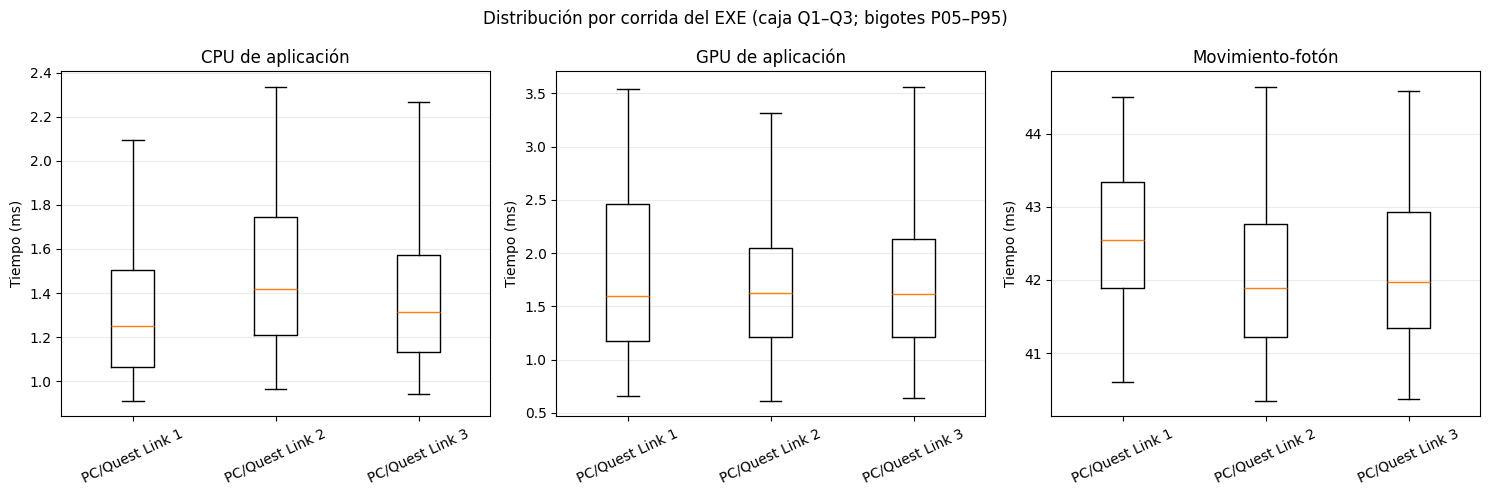

In [19]:
fig, axs = plt.subplots(1, 3, figsize=(15, 5))
for ax, (col, titulo) in zip(axs, [
    ("AppCpuElapsedTime_ms", "CPU de aplicación"),
    ("AppGpuElapsedTime_ms", "GPU de aplicación"),
    ("AppMotionToPhotonLatency_ms", "Movimiento-fotón"),
]):
    datos = [df[col].dropna().to_numpy() for df in profiler_runs.values()]
    ax.boxplot(datos, tick_labels=list(profiler_runs), showfliers=False, whis=(5, 95))
    ax.set(title=titulo, ylabel="Tiempo (ms)")
    ax.tick_params(axis="x", rotation=25)
    ax.grid(axis="y", alpha=.25)
fig.suptitle("Distribución por corrida del EXE (caja Q1–Q3; bigotes P05–P95)")
fig.tight_layout()
fig.savefig(OUT / "exe_distribuciones_metricas.png", dpi=200, bbox_inches="tight")
plt.show()

En el diagrama de caja de distribución por corrida del CPU. La segunda corrida tiene al mediana de procesamiento de CPU más alta, con 1.416 ms, luego tercera con 1.312 ms y la primera de 1.252 ms. Los rangos son similares, lo que indica que en la mayor parte de las capturas, los tiempos de procesamiento de GPU no presentaron diferencias importantes.

### 5.3. Actividad de ASW

El porcentaje de muestras con ASW activo ayuda a reconocer cuándo el sistema recurrió a esta técnica durante la captura. Su presencia es una señal para examinar la estabilidad del rendimiento, pero no demuestra por sí sola un fallo de la experiencia.

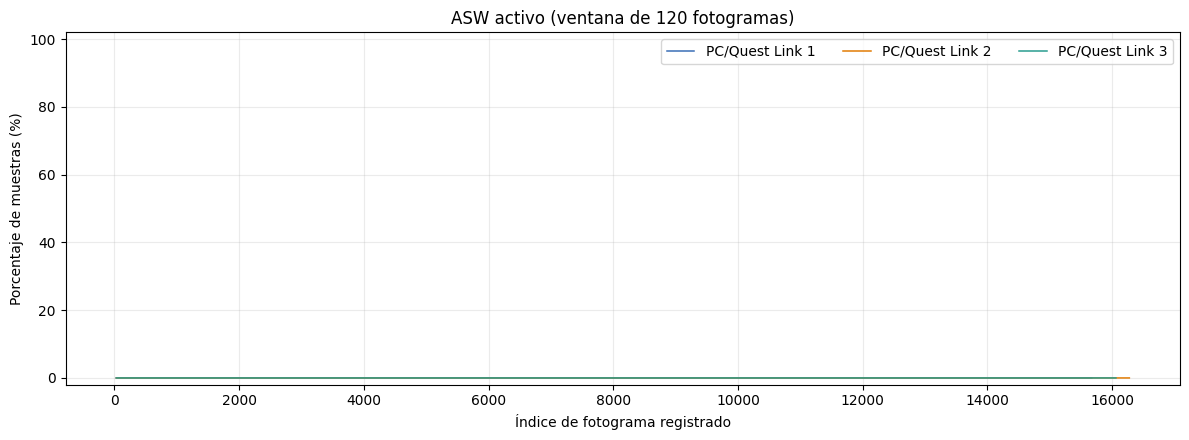

In [20]:
fig, ax = plt.subplots(figsize=(12, 4.5))
for i, (nombre, df) in enumerate(profiler_runs.items()):
    porcentaje = 100 * df["AswIsActive_num"].rolling(120, min_periods=30).mean()
    ax.plot(df["AppFrameIndex"], porcentaje,
            color=COLORS[i % len(COLORS)], linewidth=1.1, label=nombre)
ax.set(title="ASW activo (ventana de 120 fotogramas)",
       xlabel="Índice de fotograma registrado", ylabel="Porcentaje de muestras (%)", ylim=(-2, 102))
ax.legend(ncol=3)
ax.grid(alpha=.25)
fig.tight_layout()
fig.savefig(OUT / "exe_asw_evolucion.png", dpi=200, bbox_inches="tight")
plt.show()

La actividad ASW se mantuvo en las tres capturas en 0%, lo que indica uqe no se registró el uso de esta técnica de generación de fotogramas en las capturas. Lo que permite identificar que ASW no intervino en el rendimiento. A pesar de su ausencia esto no garantiza q2ue todos los fotogramas se hayan presentado correctamente, ya que los contadores del profiler registraron algunos descartes. 

### 6. Análisis de 3 esultados de APK en Quest 3S

En esta parte se muestran las mediciones tomadas directamente desde Meta Quest 3S. Se revisan principalmente los FPS, el tiempo de GPU, la utilización de CPU/GPU y el uso de memoria. Las capturas tienen su propio tiempo de inicio, por lo que las gráficas no se interpretan como una línea de tiempo sincronizada con la canción.

In [21]:
# resumen por corrida 
display(ovr_summary.round(3))

,corrida,muestras,duracion_captura_s,paso_muestreo_mediano_s,FPS_media,FPS_mediana,FPS_p05,FPS_p95,muestras_bajo_72FPS_pct,muestras_bajo_64_8FPS_pct,GPU_mediana_ms,GPU_p95_ms,muestras_GPU_sobre_presupuesto_pct,CPU_utilizacion_mediana_pct,GPU_utilizacion_mediana_pct,PSS_mediana_MB,RSS_mediana_MB,USS_mediana_MB,frames_obsoletos_mediana,shader_hitches_mediana
0,Quest 3S 1,278,277.032,1.0,70.482,72.0,54.85,73.0,17.626,10.791,6.277,16.353,10.432,72.0,52.0,1329.0,1464.0,1313.0,0.0,2.0
1,Quest 3S 2,229,228.026,1.0,69.157,72.0,49.00,73.0,20.087,14.410,6.564,19.338,13.974,36.0,55.0,1355.0,1455.0,1335.0,0.0,0.0
2,Quest 3S 3,218,218.066,1.0,69.917,72.0,55.00,73.0,22.936,12.844,6.731,15.857,10.550,33.0,55.0,1359.0,1458.0,1340.0,0.0,0.0


Las 3 capturas registraron una mediana de 72 FPS, aunque sus promedios fueron ligeramente inferiores, entre 69.157 y 70.482 FPS. Esto indica que la experiencia alcanzó con frecuencia la tasa de fotogramas objetivo, pero no logró mantenerla constantemente. Entre el 17.63% y 22.94% de las muestras estuvieron por debajo de 72 FPS. Además que la segunda corrida presentó el promedio más bajo y el percentil 95 de GPU más elevado, lo que sugiere mayores variaciones de rendimiento en esa ejecución.

In [22]:
# descripcion de cada metrica
display(ovr_descriptive.round(3))

,corrida,metrica,unidad,n,media,DE,mediana,p05,p95,minimo,maximo
0,Quest 3S 1,fps,FPS,278,70.482,5.617,72.000,54.850,73.000,43.000,73.000
1,Quest 3S 1,gpu_ms,ms,278,7.106,3.877,6.277,3.527,16.353,1.169,19.276
2,Quest 3S 1,cpu_utilization_percentage,%,278,72.094,21.602,72.000,26.000,100.000,19.000,100.000
3,Quest 3S 1,gpu_utilization_percentage,%,278,54.349,20.505,52.000,30.000,97.000,18.000,98.000
4,Quest 3S 1,app_pss_MB,MB,278,1181.129,302.254,1329.000,513.000,1548.000,513.000,1548.000
5,Quest 3S 1,app_rss_MB,MB,278,1316.388,300.622,1464.000,652.000,1682.000,652.000,1682.000
6,Quest 3S 1,app_uss_MB,MB,278,1165.266,302.187,1313.000,498.000,1532.000,498.000,1532.000
7,Quest 3S 2,fps,FPS,229,69.157,8.602,72.000,49.000,73.000,3.000,73.000
8,Quest 3S 2,gpu_ms,ms,229,8.110,4.919,6.564,1.995,19.338,0.000,30.022
9,Quest 3S 2,cpu_utilization_percentage,%,229,49.507,27.489,36.000,23.000,98.000,16.000,100.000


A pesar que la mediana de las tres pruebas fue 72 PFS, los valores mínimos registrados fueron de 43,3 y 32 FPS respectivamente. Estas diferencias demuestran que existieron caídas puntuales de rendimiento que no se reflejan en la mediana. El tiempo del GPU, presentó valores máxijmos de 30.022 ms, que es superior a sus medianas cercanas de 6-7 ms. Lo que evidencia que la carga de procesamiento no fue constante en la experienciay que existieron intervalos de mayor exigencia. 

### 6.1 fluides de la experiencia (FPS)

Se observa la variación de los FPS durante cada captura y cuántas muestras están por debajo de la referencia utilizada. Esto ayuda a identificar periodos de menor fluidez, aunque no permite por sí solo determinar qué escena los provocó.

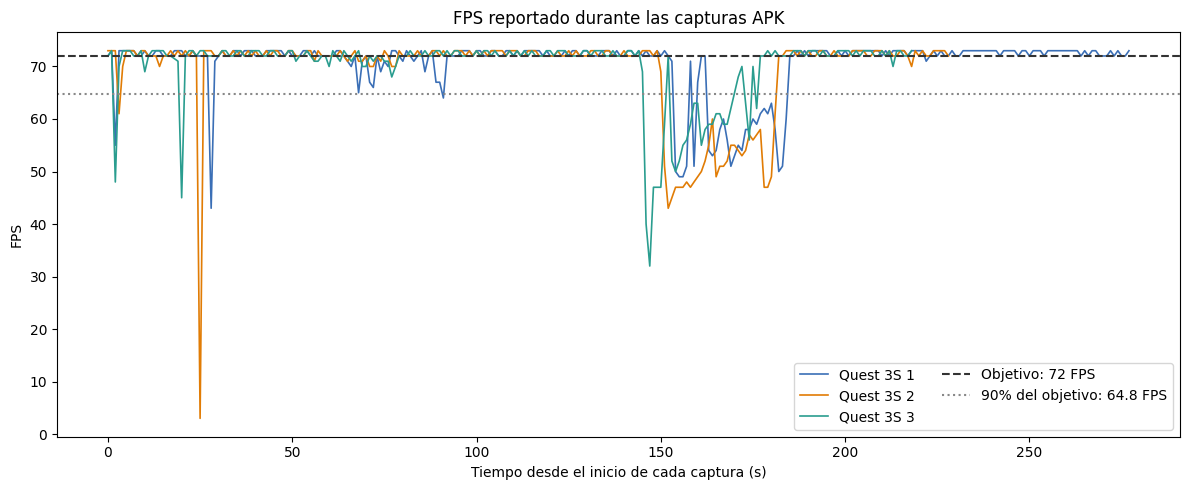

In [23]:
# FPS observado por corrida. El eje usa tiempo desde el inicio de captura, no desde el inicio musical.
fig,ax=plt.subplots(figsize=(12,5))
for i,(name,df) in enumerate(ovr_runs.items()): ax.plot(df.tiempo_captura_s,df.fps,lw=1.2,color=COLORS[i%len(COLORS)],label=name)
ax.axhline(TARGET_FPS,color="#333333",ls="--",label="Objetivo: 72 FPS")
ax.axhline(.9*TARGET_FPS,color="#888888",ls=":",label="90% del objetivo: 64.8 FPS")
ax.set(title="FPS reportado durante las capturas APK",xlabel="Tiempo desde el inicio de cada captura (s)",ylabel="FPS")
ax.legend(ncol=2); fig.tight_layout(); fig.savefig(OUT/"apk_fps_corridas.png",dpi=200,bbox_inches="tight"); plt.show()


Lo que se logra ver con el gráfico de FPS reportado durante las capturas APK, la tasa de fotogramas se mantiene cercana alos 72 FPS, Sin embargo, se observan caidas al inicio y un periodo de menor fluidez aproximadamente entre los 145 y 185 segundos, donde los valores disminuyen considerablemente. Luego, las capturas regresan a los 72 FPS. Esto indica que la experiencia pudo mantener una tasa de fotogramas adecuada durante varios intervalos, aunque presentó dificultades para mantenerla en momentos determinados de la experiencia.

### 6.2 Tiempo de GPU y uso de los recursos

Se revisa cuánto tarda la GPU en procesar la información y cómo varía la utilización de CPU y GPU. La línea de referencia del tiempo por fotograma se calcula con base en 72 Hz y debe leerse como una orientación, no como prueba automática de que se perdió un fotograma.


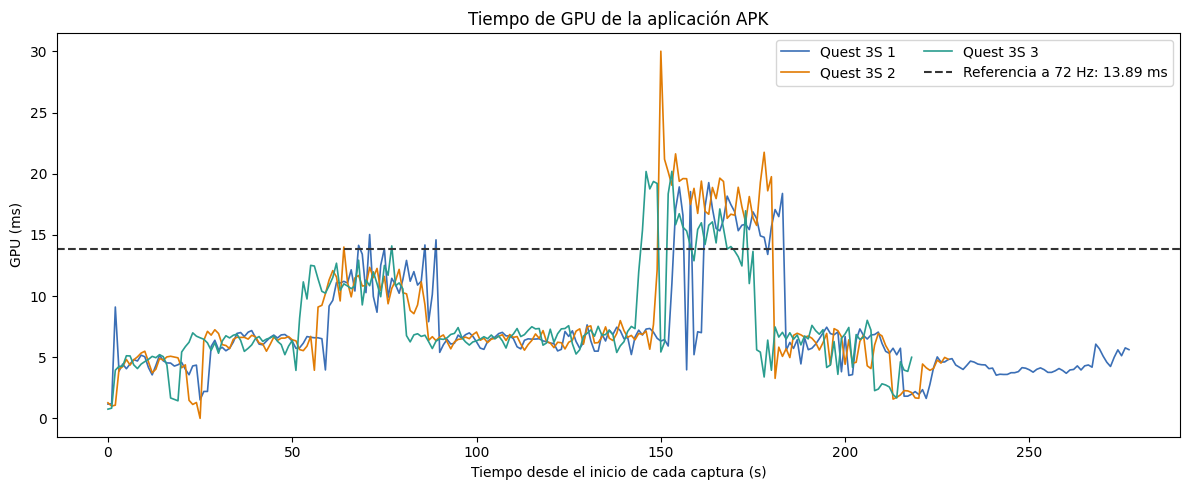

In [26]:
fig, ax = plt.subplots(figsize=(12, 5))
for i, (nombre, df) in enumerate(ovr_runs.items()):
    ax.plot(df["tiempo_captura_s"], df["gpu_ms"], linewidth=1.2,
            color=COLORS[i % len(COLORS)], label=nombre)
ax.axhline(GPU_BUDGET_MS, color="#333333", linestyle="--",
           label=f"Referencia a {TARGET_FPS:g} Hz: {GPU_BUDGET_MS:.2f} ms")
ax.set(title="Tiempo de GPU de la aplicación APK",
       xlabel="Tiempo desde el inicio de cada captura (s)", ylabel="GPU (ms)")
ax.legend(ncol=2)
fig.tight_layout()
fig.savefig(OUT / "apk_gpu_tiempo_corridas.png", dpi=200, bbox_inches="tight")
plt.show()



El tiempo de procesamiento de GPU se mantiene entre 4 a 8 ms, pero hay varios incrementos importantes en ciertos intervalos. El aumento más grande es entre los 145 y 180 segundos. Donde varias mediciones superan la referencia a 72 Hz, que es 13.89 ms. Y esos incrementos coinciden las disminuciones de FPS como se observa en la gráfica de FPS reportado durante las capturas APK.

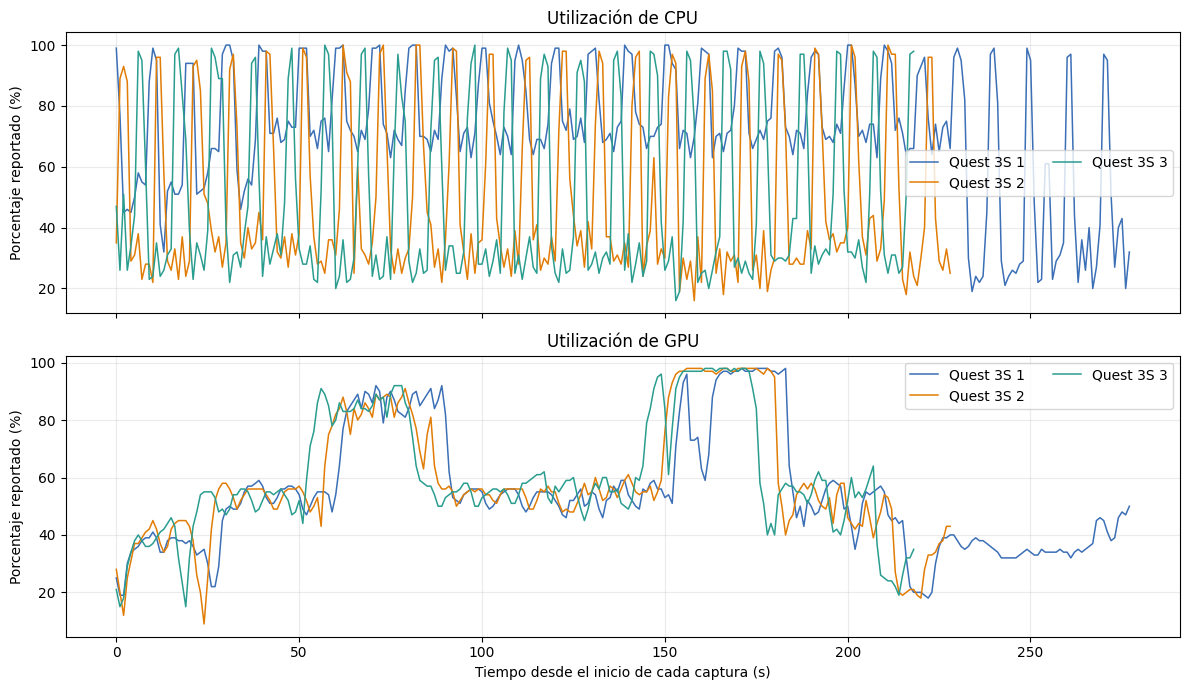

In [27]:
fig, axs = plt.subplots(2, 1, figsize=(12, 7), sharex=True)
for i, (nombre, df) in enumerate(ovr_runs.items()):
    color = COLORS[i % len(COLORS)]
    axs[0].plot(df["tiempo_captura_s"], df["cpu_utilization_percentage"], color=color, linewidth=1.1, label=nombre)
    axs[1].plot(df["tiempo_captura_s"], df["gpu_utilization_percentage"], color=color, linewidth=1.1, label=nombre)
axs[0].set(title="Utilización de CPU", ylabel="Porcentaje reportado (%)")
axs[1].set(title="Utilización de GPU", ylabel="Porcentaje reportado (%)",
           xlabel="Tiempo desde el inicio de cada captura (s)")
for ax in axs:
    ax.legend(ncol=2)
    ax.grid(alpha=.25)
fig.tight_layout()
fig.savefig(OUT / "apk_utilizacion_corridas.png", dpi=200, bbox_inches="tight")
plt.show()

En la gráfica de utilización de CPU se ven muchas variaciones frecuentes durante todas las capturas, altenrando entre niveles moderados y valores cercanos al 100%. En la primera corrida se muestra una mediana de uso mayor que en las otras dos, donde alcanza el 72% frente a 36% y 33%. Lo que indica que la carga del procesamiento reportada para la CPU no fue uniforme en las ejecuciones. Aunque con estos valores no se puede determinar por si solos que la CPU haya sido responsable de los bajones de FPS.


Mientras que en la gráfica de GPU se puede observar que el uso de la GPU presenta niveles intermedios en una gran parte de las capturas, con medianas cercanas al 52% y 55%. Aunque, se puede observar incrementos que alcanzan 95-98% en algunos intervalos, como entre los 150 a 180 segundos. Que son los periodos que coinciden con los aumentos de tiempo de GPU y las reducciones de FPS. Por lo tanto, los resultados sugieren que la carga gráfica fue un factor importante durante los momentos de menor rendimiento. 

### 6.3 Uso de memoria
se revisan las distintas mediciones de memoria del proceso (PSS, RSS y USS). Estas métricas no representan exactamente lo mismo, por lo que se muestran por separado y se comparan únicamente entre capturas del APK.

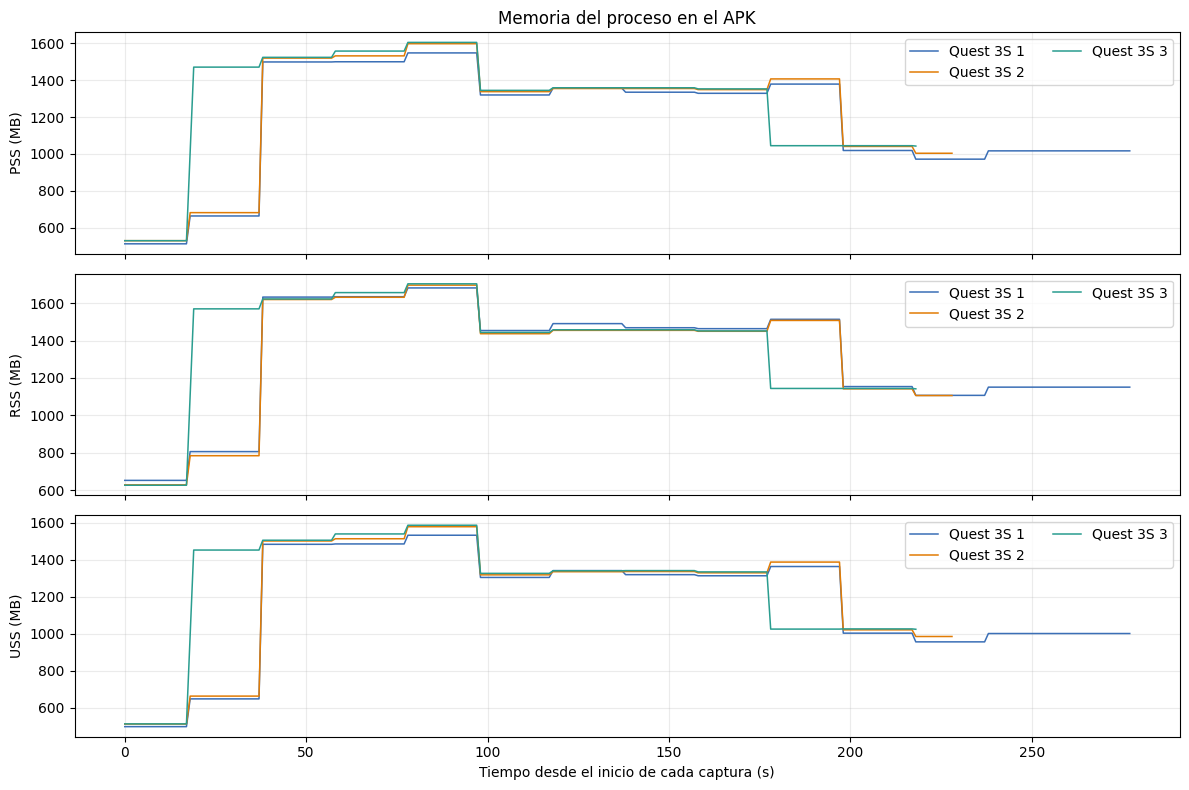

In [25]:
fig, axs = plt.subplots(3, 1, figsize=(12, 8), sharex=True)
for i, (nombre, df) in enumerate(ovr_runs.items()):
    for ax, col in zip(axs, ["app_pss_MB", "app_rss_MB", "app_uss_MB"]):
        ax.plot(df["tiempo_captura_s"], df[col], linewidth=1.1,
                color=COLORS[i % len(COLORS)], label=nombre)
for ax, etiqueta in zip(axs, ["PSS", "RSS", "USS"]):
    ax.set_ylabel(f"{etiqueta} (MB)")
    ax.legend(ncol=2)
    ax.grid(alpha=.25)
axs[0].set_title("Memoria del proceso en el APK")
axs[-1].set_xlabel("Tiempo desde el inicio de cada captura (s)")
fig.tight_layout()
fig.savefig(OUT / "apk_memoria_corridas.png", dpi=200, bbox_inches="tight")
plt.show()

En la gráfica de memoria del proceso en el APK, acerca de la memoria RSS muestra un comportamiento similar al de PSS, aunque con algunos valores superiores que llega a alcanzar sus máximos que son entre 1,682 y 1,704 MB. Su evolución muestra incrementos iniciales, periodos de estabilidad y reducciones que se se ven subsecuentemente se ven reducciones que llevan a el consumo vercano a 1,300 MB y finalmente alrededor de 1,000 MB. Este comportamiento lo que indica es que el uso de la memoria cambió durante la ejecución. 

En el uso de memoria PSS se presenta un crecimiento inicial por etapas, que pasa de 500 MB a 1,605 MB. Luego se observar reducciones que llevan al consumo a niveles cercanos de 1,300 MB y luego al final de 1000 MB. Este comportamiento lo que indica es que el uso de memoria cambio durante la ejecución.
Esto puede ser al uso y liberación de recursos. 

Acercsa de la gráfica de memoria USS, se ve un crecimiento muy parecido a las gráfica de la memoria PSS y RSS, con incrementos que llegan a los valores máximos de 1,532 y 1,586 MB, seguido de reducciones posteriores. Esto lo que indica es que la memoria privada utilizada por la aplicación cambió durante la ejecución. Ya que no se observa un crecimiento continuo hasta el final de las capturas, estas mediciones no dan la suficiente evidencia para decir que hubo una fuga de memoria. 

